# Lab 5 - Zadanie

In [1]:
!pip install torch torchvision matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from google.colab import files
from matplotlib.patches import Rectangle
from PIL import Image
from torchvision.models import ResNet18_Weights, resnet18

print("PyTorch:", torch.__version__)

PyTorch: 2.14.1+cpu


## 1. Zdjęcie

Saving książki.png to książki.png
Rozmiar zdjęcia: 867 x 1500
Wybrany fragment: 210 x 320


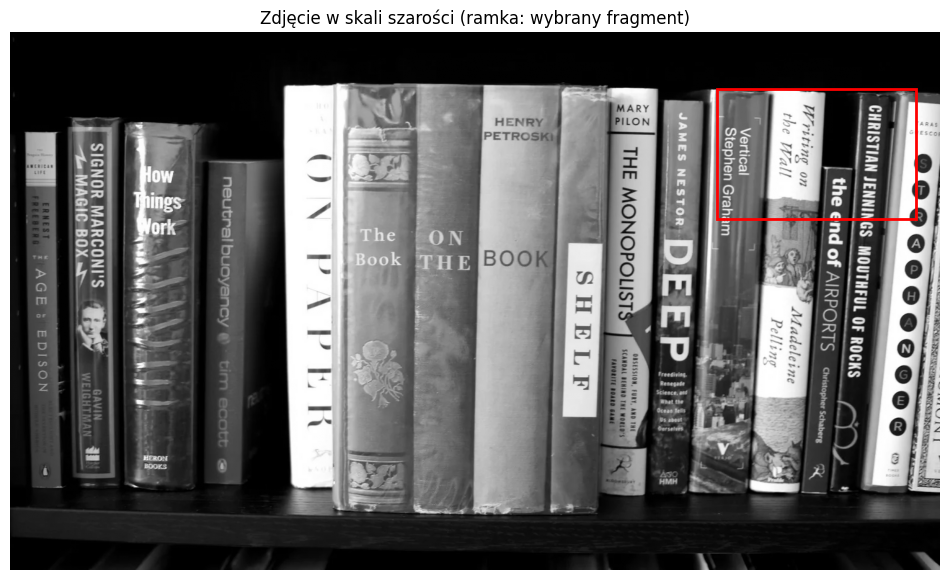

In [3]:
uploaded = files.upload()
photo = Image.open(next(iter(uploaded))).convert("L")
gray = torch.from_numpy(np.array(photo)).float().div(255)[None, None]
H, W = gray.shape[-2:]
Y0, Y1, X0, X1 = 90, 300, 1140, 1460
print("Rozmiar zdjęcia:", H, "x", W)
print("Wybrany fragment:", Y1 - Y0, "x", X1 - X0)

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(gray[0, 0], cmap="gray", vmin=0, vmax=1)
ax.add_patch(Rectangle((X0, Y0), X1 - X0, Y1 - Y0,
                       fill=False, edgecolor="red", linewidth=2))
ax.set_title("Zdjęcie w skali szarości (ramka: wybrany fragment)")
ax.axis("off")
plt.show()

## 2. Ręczne jądra

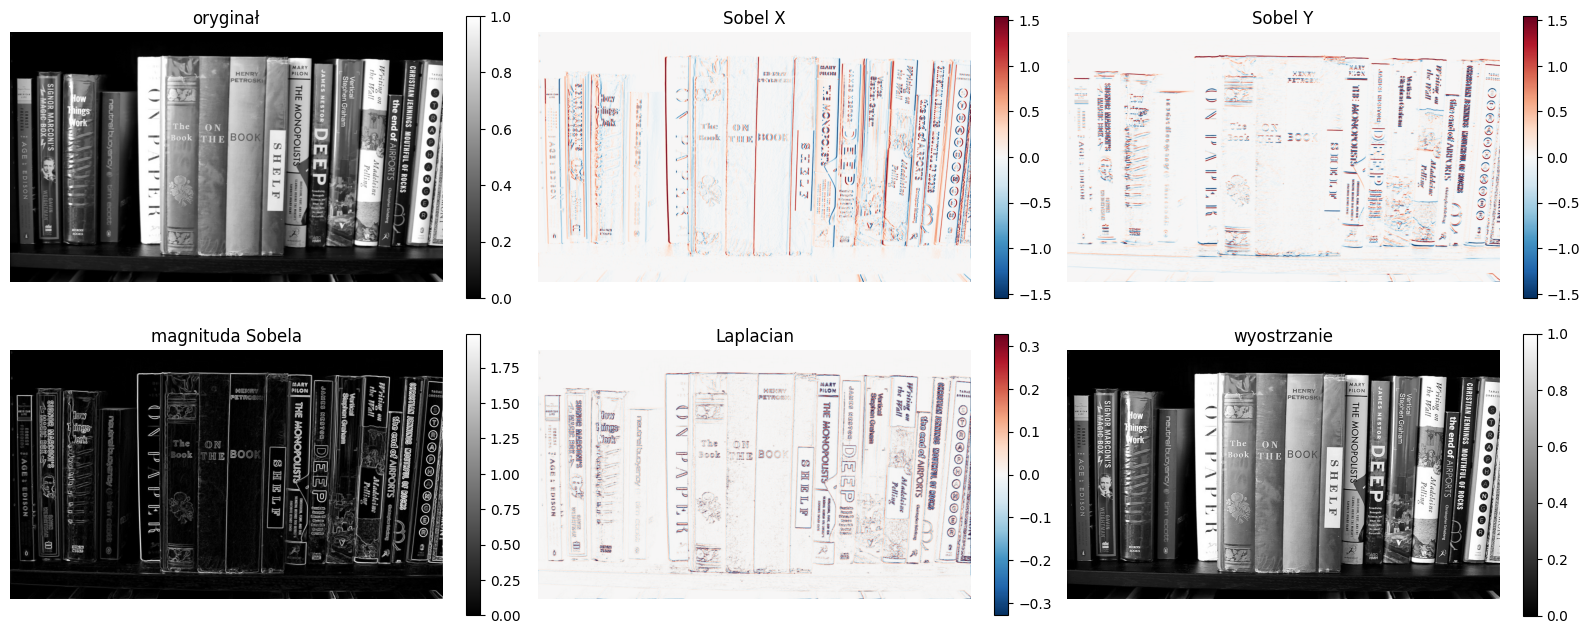

In [4]:
def kernel(values):
    return torch.tensor(values, dtype=torch.float32)[None, None]


sobel_x = kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = sobel_x.transpose(-2, -1)
laplace = kernel([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
sharpen = kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
magnitude = (gx ** 2 + gy ** 2).sqrt()
lap = F.conv2d(gray, laplace, padding=1)
sharp = F.conv2d(gray, sharpen, padding=1).clamp(0, 1)

g_max = torch.quantile(torch.cat([gx.abs().flatten(),
                                  gy.abs().flatten()]), 0.99).item()
m_max = torch.quantile(magnitude.flatten(), 0.99).item()
l_max = torch.quantile(lap.abs().flatten(), 0.99).item()
panels = [
    ("oryginał", gray, "gray", 0, 1),
    ("Sobel X", gx, "RdBu_r", -g_max, g_max),
    ("Sobel Y", gy, "RdBu_r", -g_max, g_max),
    ("magnituda Sobela", magnitude, "gray", 0, m_max),
    ("Laplacian", lap, "RdBu_r", -l_max, l_max),
    ("wyostrzanie", sharp, "gray", 0, 1),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for ax, (name, img, cmap, lo, hi) in zip(axes.flat, panels):
    im = ax.imshow(img[0, 0], cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(name)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.show()

## 3. Wzór na wymiary wyjścia

In [5]:
def out_size(n, k, s=1, p=0, d=1):
    return (n + 2 * p - d * (k - 1) - 1) // s + 1


configs = [
    (3, 1, 0, 1),
    (3, 1, 1, 1),
    (5, 2, 2, 1),
    (3, 1, 2, 2),
    (7, 3, 0, 1),
    (4, 2, 1, 3),
]
rows = []
with torch.no_grad():
    for k, s, p, d in configs:
        conv = nn.Conv2d(1, 1, k, stride=s, padding=p, dilation=d)
        h, w = conv(gray).shape[-2:]
        fh, fw = out_size(H, k, s, p, d), out_size(W, k, s, p, d)
        rows.append({"k": k, "stride": s, "padding": p, "dilation": d,
                     "wzór": f"{fh} x {fw}", "nn.Conv2d": f"{h} x {w}",
                     "zgodne": (fh, fw) == (h, w)})
print("Wejście:", H, "x", W)
pd.DataFrame(rows)

Wejście: 867 x 1500


,k,stride,padding,dilation,wzór,nn.Conv2d,zgodne
0,3,1,0,1,865 x 1498,865 x 1498,True
1,3,1,1,1,867 x 1500,867 x 1500,True
2,5,2,2,1,434 x 750,434 x 750,True
3,3,1,2,2,867 x 1500,867 x 1500,True
4,7,3,0,1,287 x 498,287 x 498,True
5,4,2,1,3,430 x 747,430 x 747,True


## 4. Stride, padding i dilation

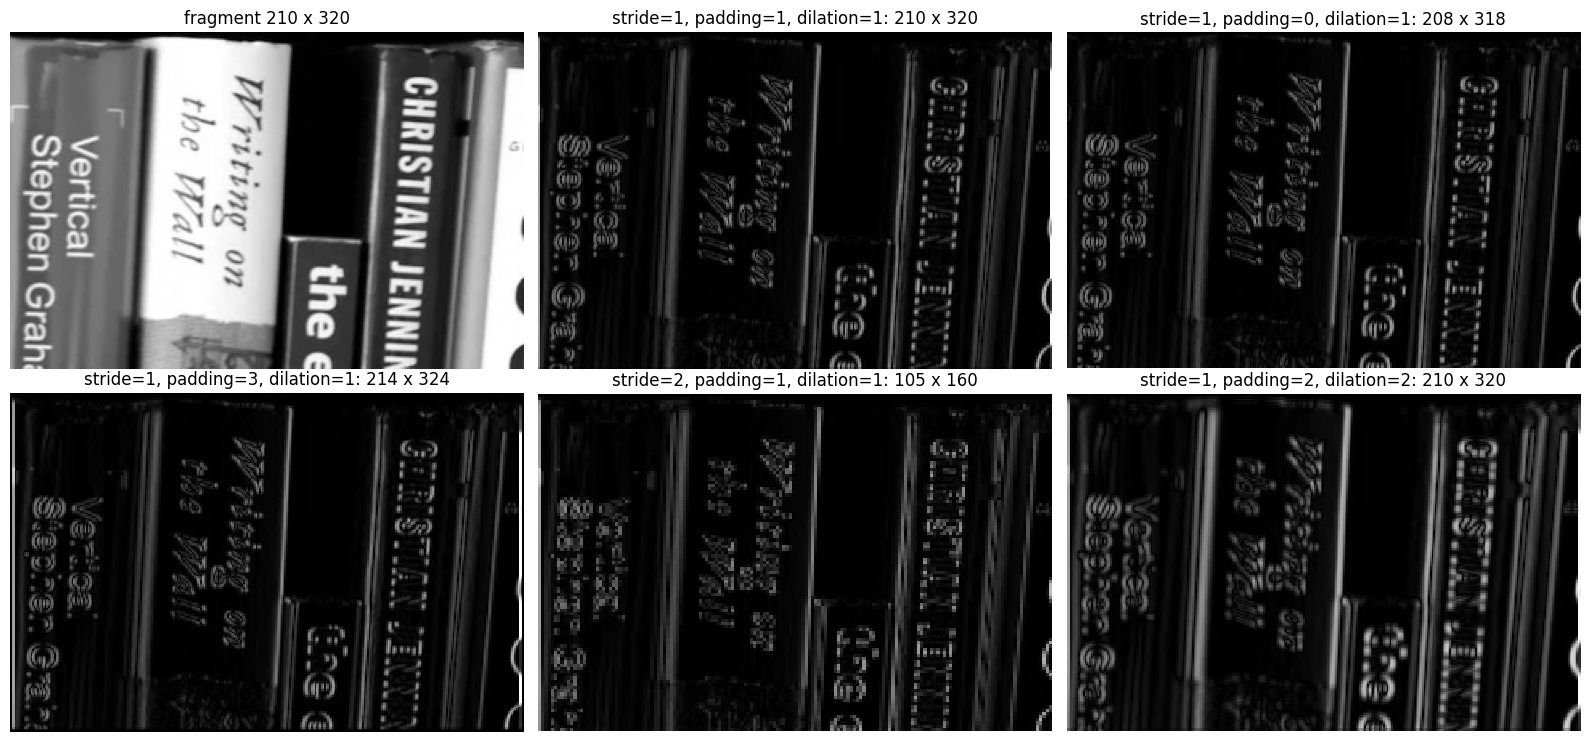

In [6]:
fragment = gray[..., Y0:Y1, X0:X1]
settings = [
    (1, 1, 1),
    (1, 0, 1),
    (1, 3, 1),
    (2, 1, 1),
    (1, 2, 2),
]
outs = [F.conv2d(fragment, sobel_x, stride=s, padding=p, dilation=d).abs()
        for s, p, d in settings]
v_max = max(out.max() for out in outs).item()

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
axes[0, 0].imshow(fragment[0, 0], cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title(f"fragment {Y1 - Y0} x {X1 - X0}")
for ax, (s, p, d), out in zip(axes.flat[1:], settings, outs):
    h, w = out.shape[-2:]
    ax.imshow(out[0, 0], cmap="gray", vmin=0, vmax=v_max,
              interpolation="nearest")
    ax.set_title(f"stride={s}, padding={p}, dilation={d}: {h} x {w}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Mapy cech ResNet-18

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 141MB/s]


Wejście sieci: (1, 3, 224, 388)
Mapy cech conv1: (64, 112, 194)


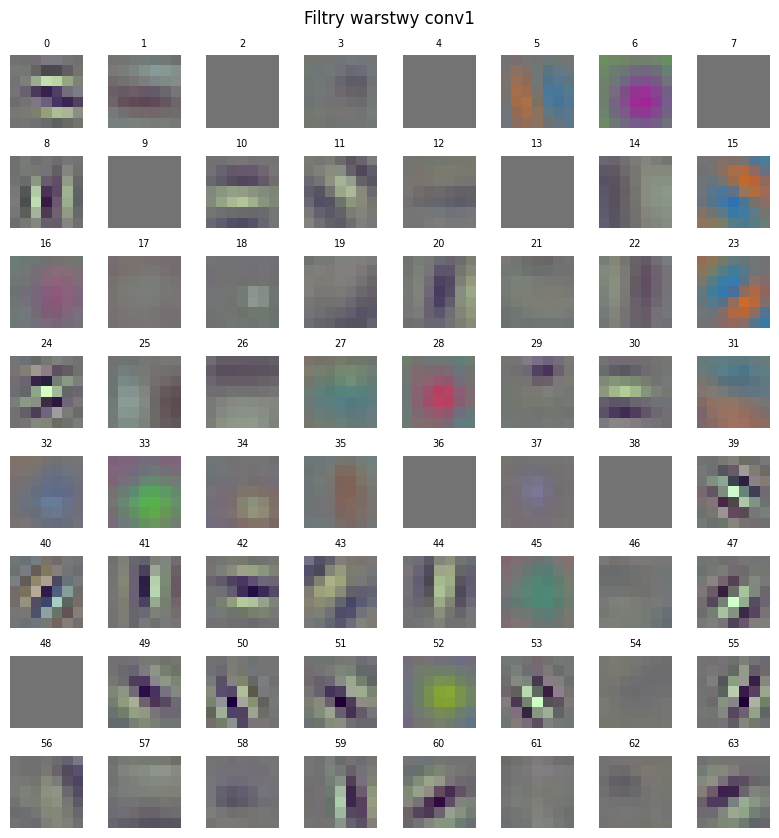

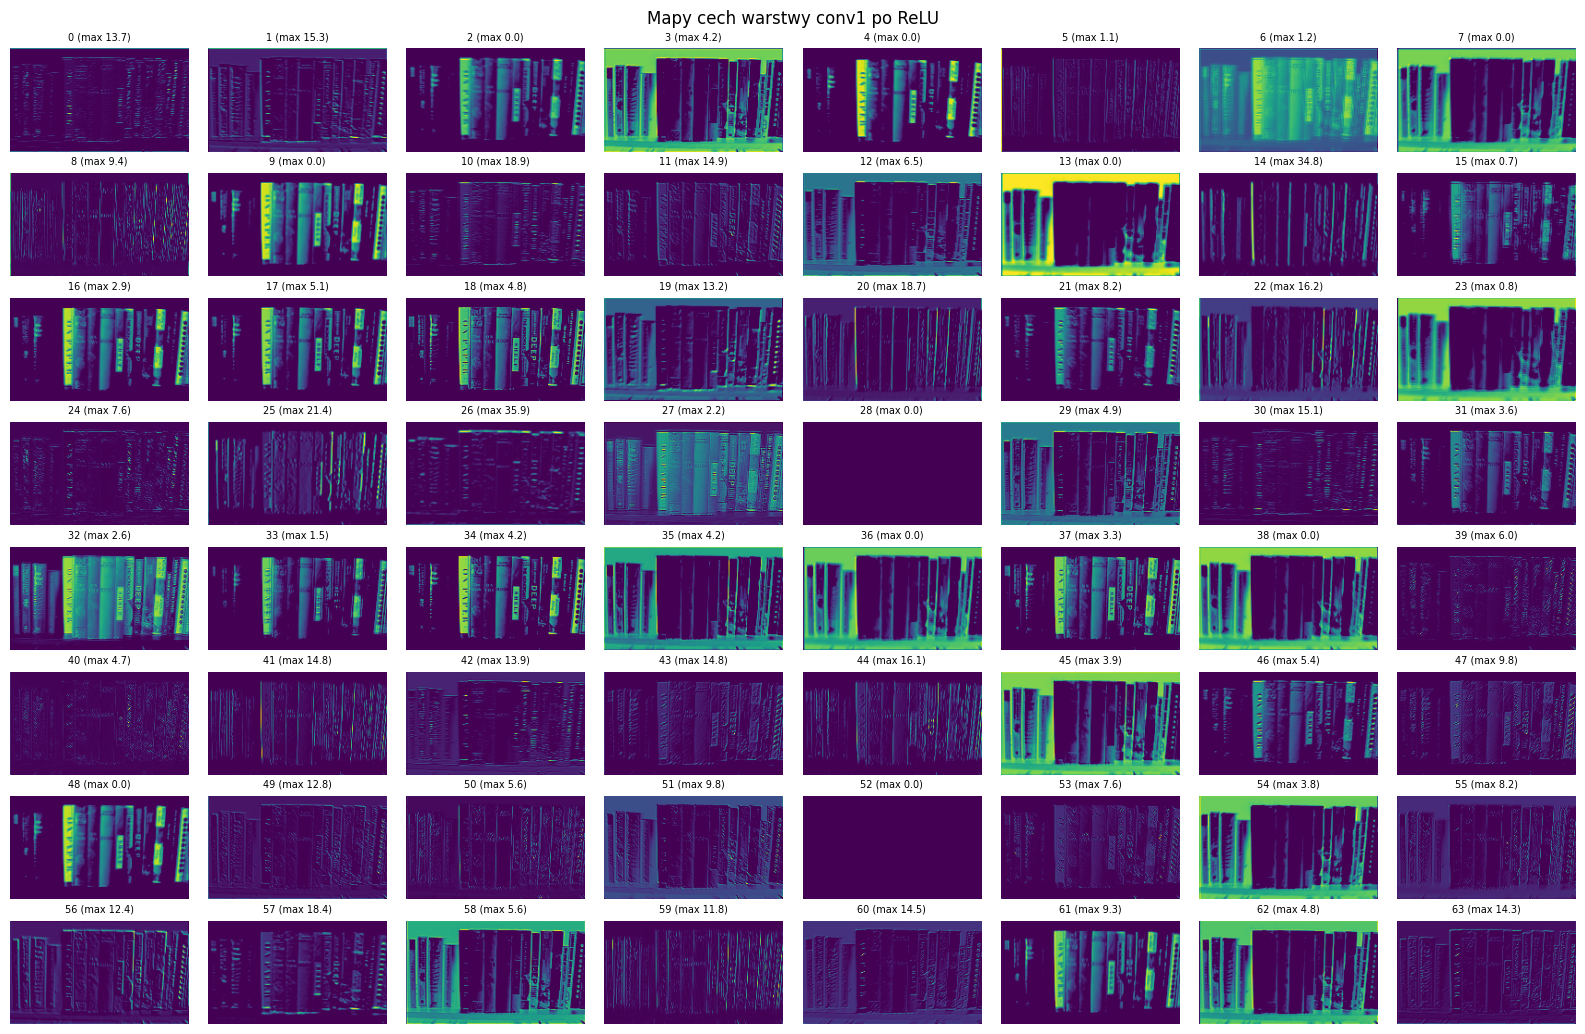

In [7]:
model = resnet18(weights=ResNet18_Weights.DEFAULT).eval()
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
small = F.interpolate(gray, size=(224, round(224 * W / H)),
                      mode="bilinear", antialias=True)
x = (small.repeat(1, 3, 1, 1) - mean) / std
with torch.no_grad():
    maps = torch.relu(model.conv1(x))[0]
print("Wejście sieci:", tuple(x.shape))
print("Mapy cech conv1:", tuple(maps.shape))

w = model.conv1.weight.detach()
w = (w - w.min()) / (w.max() - w.min())
fig, axes = plt.subplots(8, 8, figsize=(8, 8.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(w[i].permute(1, 2, 0))
    ax.set_title(str(i), fontsize=7)
    ax.axis("off")
fig.suptitle("Filtry warstwy conv1")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(8, 8, figsize=(16, 10.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[i], cmap="viridis")
    ax.set_title(f"{i} (max {maps[i].max():.1f})", fontsize=7)
    ax.axis("off")
fig.suptitle("Mapy cech warstwy conv1 po ReLU")
plt.tight_layout()
plt.show()

## 6. Filtry rozmywające

Wagi Gaussian 5x5 pomnożone przez 256:
tensor([[ 1,  4,  6,  4,  1],
        [ 4, 16, 24, 16,  4],
        [ 6, 24, 36, 24,  6],
        [ 4, 16, 24, 16,  4],
        [ 1,  4,  6,  4,  1]], dtype=torch.int32)
Box 3x3: padding=1, wyjście (867, 1500)
Box 5x5: padding=2, wyjście (867, 1500)
Gaussian 5x5: padding=2, wyjście (867, 1500)


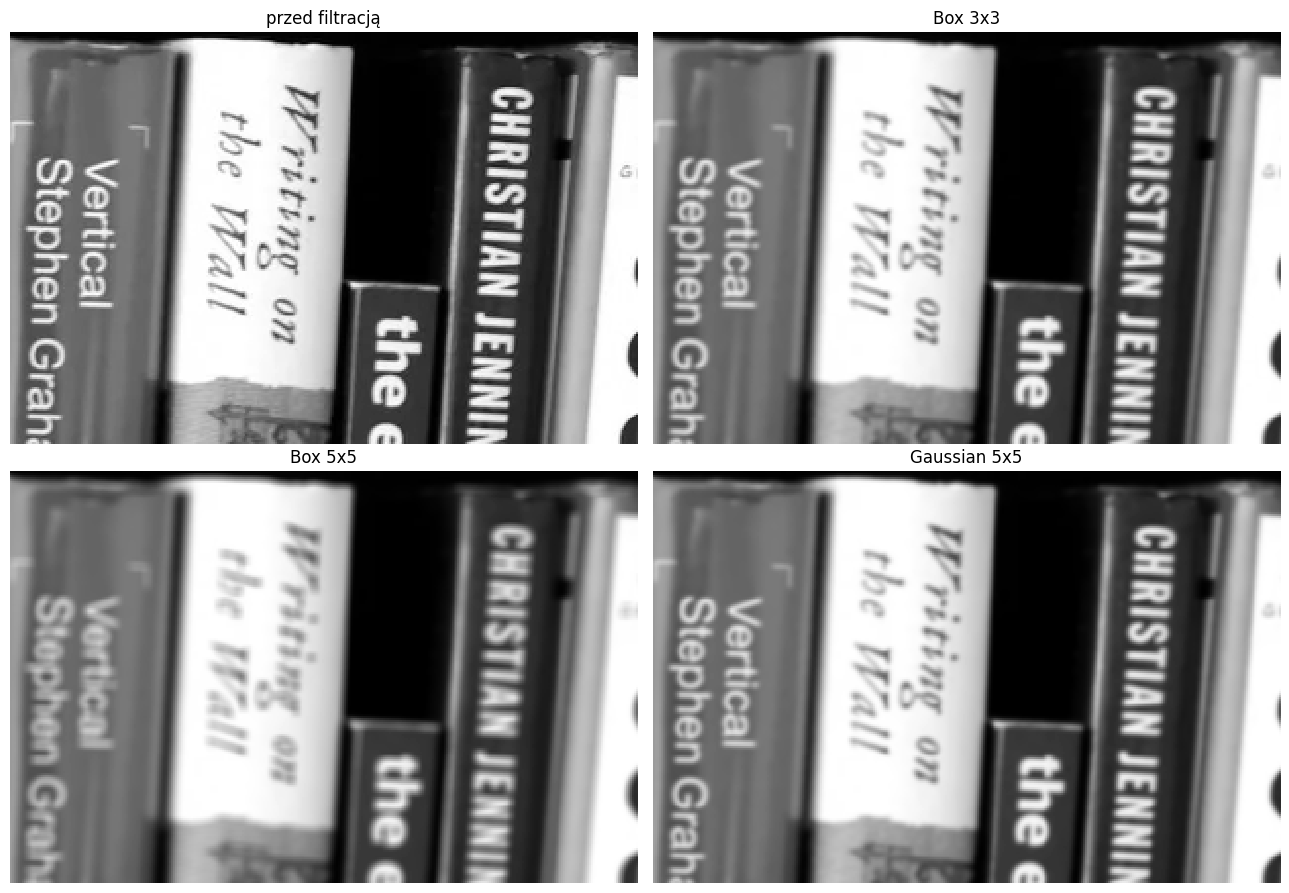

In [8]:
g1 = torch.tensor([1.0, 4.0, 6.0, 4.0, 1.0])
blurs = {
    "Box 3x3": torch.full((1, 1, 3, 3), 1 / 9),
    "Box 5x5": torch.full((1, 1, 5, 5), 1 / 25),
    "Gaussian 5x5": (torch.outer(g1, g1) / 256)[None, None],
}
print("Wagi Gaussian 5x5 pomnożone przez 256:")
print((blurs["Gaussian 5x5"][0, 0] * 256).int())

panels = {"przed filtracją": gray}
for name, k in blurs.items():
    pad = k.shape[-1] // 2
    out = F.conv2d(gray, k, stride=1, padding=pad, dilation=1)
    print(f"{name}: padding={pad}, wyjście {tuple(out.shape[-2:])}")
    panels[name] = out

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (name, img) in zip(axes.flat, panels.items()):
    ax.imshow(img[0, 0, Y0:Y1, X0:X1], cmap="gray", vmin=0, vmax=1,
              interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()